In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATASET_PATH = Path(r"C:\Users\Lenovo\Desktop\projecr\bot_detection_data.csv")
if not DATASET_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATASET_PATH}")


df = pd.read_csv(DATASET_PATH)

df["Created At"] = pd.to_datetime(
    df["Created At"],
    errors="coerce"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Date range:")
print("Start:", df["Created At"].min())
print("End:", df["Created At"].max())
print("Invalid timestamps:", df["Created At"].isna().sum())

Dataset loaded successfully!
Dataset shape: (50000, 11)
Date range:
Start: 2020-01-01 00:44:14
End: 2023-05-31 07:53:27
Invalid timestamps: 0


In [3]:
tweets_per_user = df.groupby("User ID").size()

print("Total tweets:", len(df))
print("Unique users:", df["User ID"].nunique())
print("Users with exactly one tweet:", (tweets_per_user == 1).sum())
print("Users with multiple tweets:", (tweets_per_user > 1).sum())

print("\nTweets per user distribution:")
print(tweets_per_user.value_counts().sort_index())

Total tweets: 50000
Unique users: 50000
Users with exactly one tweet: 50000
Users with multiple tweets: 0

Tweets per user distribution:
1    50000
Name: count, dtype: int64


In [4]:
daily_activity = (
    df.set_index("Created At")
      .resample("D")
      .size()
)

print(daily_activity.describe())

count    1247.000000
mean       40.096231
std         6.428921
min        20.000000
25%        36.000000
50%        40.000000
75%        44.000000
max        65.000000
dtype: float64


In [5]:
hourly_activity = (
    df.set_index("Created At")
      .resample("h")
      .size()
)

print(hourly_activity.describe())

count    29912.000000
mean         1.671570
std          1.295413
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          8.000000
dtype: float64


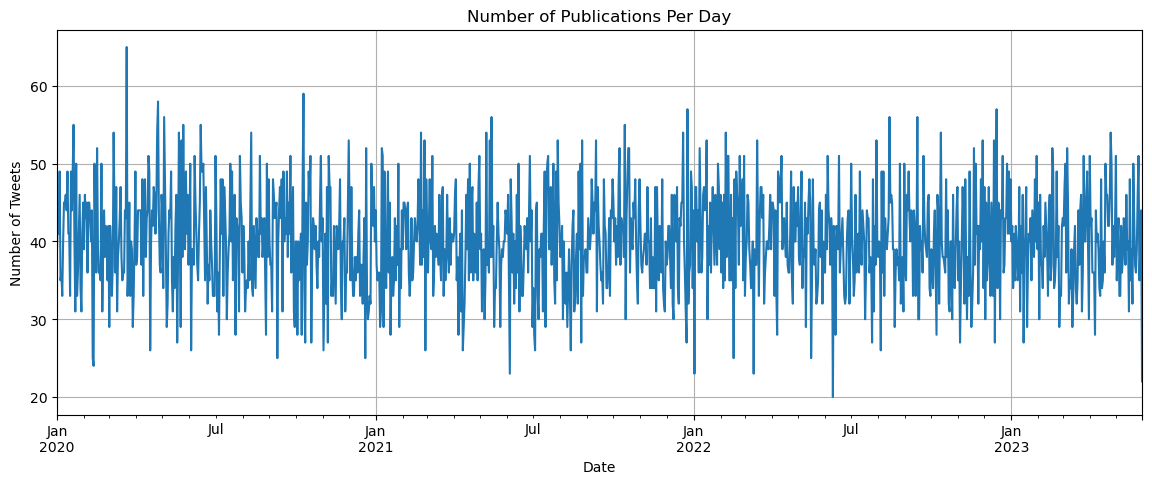

In [6]:
plt.figure(figsize=(14, 5))

daily_activity.plot()

plt.title("Number of Publications Per Day")
plt.xlabel("Date")
plt.ylabel("Number of Tweets")
plt.grid(True)

plt.show()

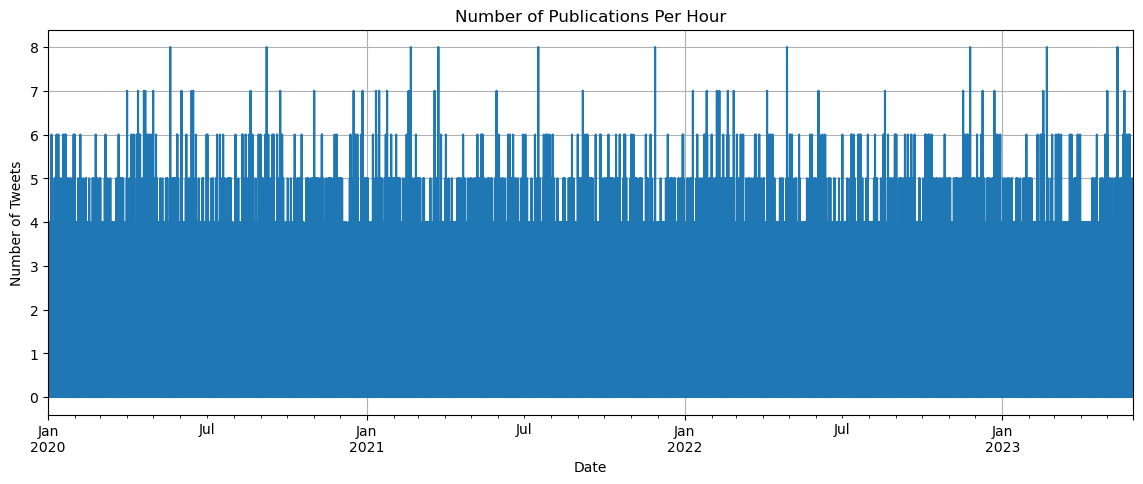

In [7]:
plt.figure(figsize=(14, 5))

hourly_activity.plot()

plt.title("Number of Publications Per Hour")
plt.xlabel("Date")
plt.ylabel("Number of Tweets")
plt.grid(True)

plt.show()